In [8]:
# !pip install scikit-tree

In [9]:
from pathlib import Path
import sys

# Add parent directory to path to import local forestgap package
sys.path.insert(0, str(Path.cwd().parent))

from forestgap import with_sparse_proximity

In [10]:
import numpy as np
from sktree import ObliqueRandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification

# Generate some example data
X, y = make_classification(n_samples=100, n_features=4,
                           n_informative=2, n_redundant=0,
                           random_state=0, shuffle=False)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

# Create an instance of the ObliqueRandomForestClassifier
# You can adjust parameters like n_estimators (number of trees)
oblique_forest = ObliqueRandomForestClassifier(n_estimators=100, random_state=0)

oblique_forest = with_sparse_proximity(oblique_forest)

# Train the model
oblique_forest.fit(X_train, y_train)

# Make predictions
predictions = oblique_forest.predict(X_test)

# Evaluate the model
accuracy = oblique_forest.score(X_test, y_test)
print(f"Model accuracy: {accuracy}")


Model accuracy: 0.8787878787878788


In [19]:
prox_oblique = oblique_forest.get_proximities().toarray()
prox_oblique_symmetric = (prox_oblique + prox_oblique.T) / 2

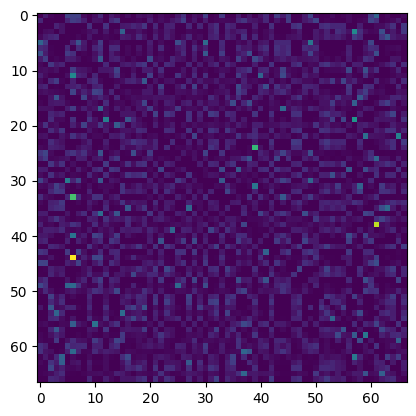

In [27]:
import matplotlib.pyplot as plt
plt.imshow(prox_oblique)

In [25]:
len(X_test)

300

ValueError: 'c' argument has 700 elements, which is inconsistent with 'x' and 'y' with size 67.

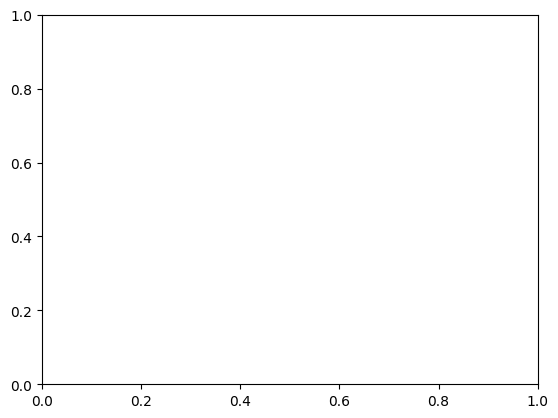

In [21]:
from sklearn.manifold import MDS

mds = MDS(n_components=2, dissimilarity='precomputed', random_state=0)
mds_coords = mds.fit_transform(1 - prox_oblique_symmetric)
import matplotlib.pyplot as plt
plt.scatter(mds_coords[:, 0], mds_coords[:, 1], c=y_train, cmap='viridis')
plt.title('MDS Projection of Oblique Random Forest Proximities')
plt.xlabel('MDS Dimension 1')
plt.ylabel('MDS Dimension 2')


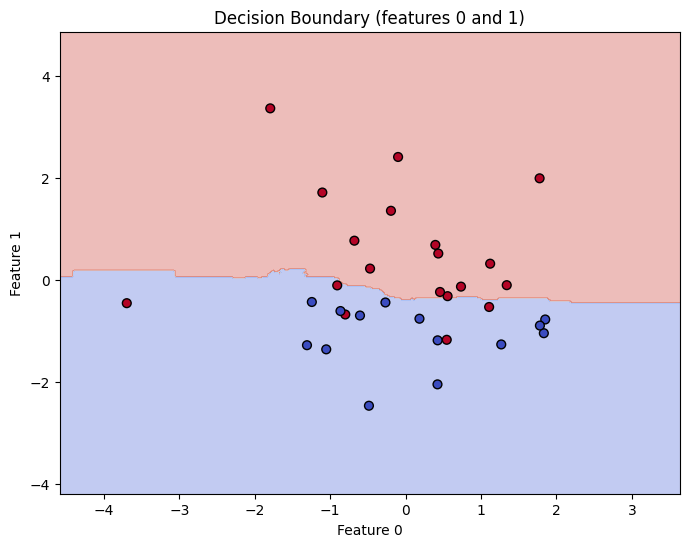

In [11]:
import matplotlib.pyplot as plt

# Plot decision boundary using first two features (fix others to training-set means)
f1, f2 = 0, 1
x_min, x_max = X_train[:, f1].min() - 1.0, X_train[:, f1].max() + 1.0
y_min, y_max = X_train[:, f2].min() - 1.0, X_train[:, f2].max() + 1.0

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

X_grid = np.tile(X_train.mean(axis=0), (xx.size, 1))
X_grid[:, f1] = xx.ravel()
X_grid[:, f2] = yy.ravel()

Z = oblique_forest.predict(X_grid).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.35, cmap="coolwarm")
plt.scatter(
    X_test[:, f1], X_test[:, f2],
    c=y_test, cmap="coolwarm", edgecolor="k", s=40
)
plt.xlabel(f"Feature {f1}")
plt.ylabel(f"Feature {f2}")
plt.title("Decision Boundary (features 0 and 1)")
plt.show()

# Extended Isolation Forest
Anomaly detection using oblique (sparse random linear combination) splits instead of axis-aligned splits.

C:\Users\rhodes8\AppData\Local\Temp\ipykernel_33820\4166507277.py:28: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(X_all[preds == -1, 0], X_all[preds == -1, 1],


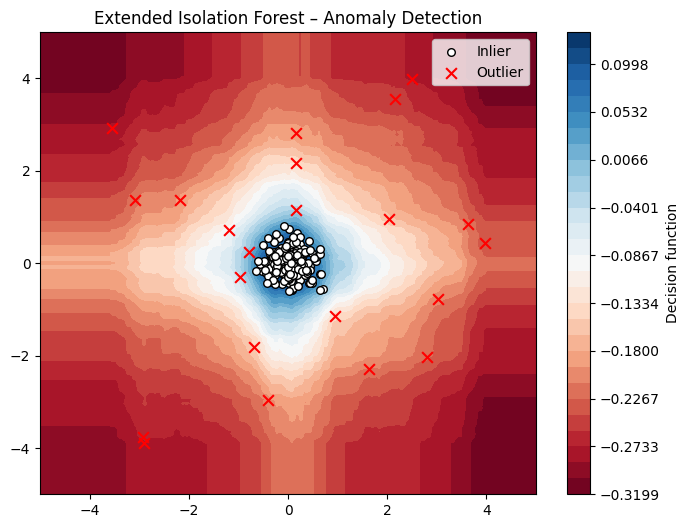

Detected 22 outliers out of 220 samples


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sktree.ensemble import ExtendedIsolationForest

# Generate normal inliers and a few outliers
rng = np.random.RandomState(42)
X_inliers = 0.3 * rng.randn(200, 2)
X_outliers = rng.uniform(low=-4, high=4, size=(20, 2))
X_all = np.vstack([X_inliers, X_outliers])

# Fit Extended Isolation Forest
eif = ExtendedIsolationForest(n_estimators=200, contamination=0.1, random_state=42)
eif.fit(X_all)

# Score every point (negative = anomaly)
scores = eif.decision_function(X_all)
preds = eif.predict(X_all)  # 1 = inlier, -1 = outlier

# Visualise decision boundary
xx, yy = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-5, 5, 200))
Z = eif.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, levels=np.linspace(Z.min(), Z.max(), 30), cmap="RdBu")
plt.colorbar(label="Decision function")
plt.scatter(X_all[preds == 1, 0], X_all[preds == 1, 1],
            c="white", edgecolor="k", s=30, label="Inlier")
plt.scatter(X_all[preds == -1, 0], X_all[preds == -1, 1],
            c="red", edgecolor="k", s=60, marker="x", label="Outlier")
plt.title("Extended Isolation Forest – Anomaly Detection")
plt.legend()
plt.show()

print(f"Detected {(preds == -1).sum()} outliers out of {len(preds)} samples")

# Honest Forest Classifier
Honest forests use separate subsets of the data for learning split rules vs. estimating leaf predictions, producing unbiased probability estimates.

Honest Forest accuracy: 0.937


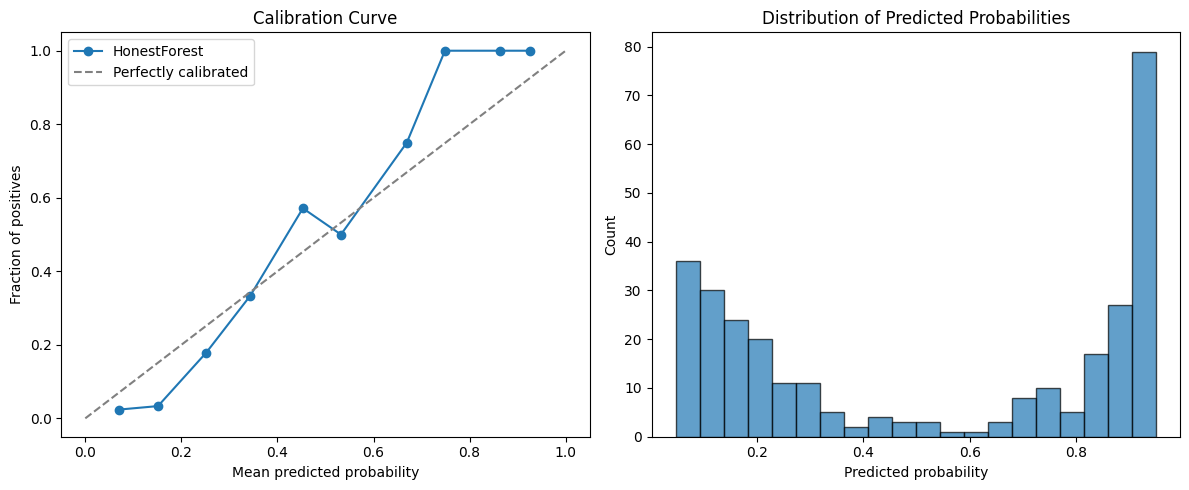

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sktree import HonestForestClassifier
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.calibration import calibration_curve

# Generate data
X, y = make_classification(n_samples=1000, n_features=10,
                           n_informative=5, n_redundant=2,
                           random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Fit an HonestForestClassifier
hfc = HonestForestClassifier(
    n_estimators=200,
    honest_fraction=0.5,   # half of each tree's data is reserved for leaf estimates
    max_depth=10,
    random_state=42,
)
hfc.fit(X_train, y_train)

# Predictions & probabilities
y_pred = hfc.predict(X_test)
y_prob = hfc.predict_proba(X_test)[:, 1]
acc = accuracy_score(y_test, y_pred)
print(f"Honest Forest accuracy: {acc:.3f}")

# Calibration curve – honest forests should produce well-calibrated probabilities
prob_true, prob_pred = calibration_curve(y_test, y_prob, n_bins=10)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: calibration plot
axes[0].plot(prob_pred, prob_true, marker="o", label="HonestForest")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Perfectly calibrated")
axes[0].set_xlabel("Mean predicted probability")
axes[0].set_ylabel("Fraction of positives")
axes[0].set_title("Calibration Curve")
axes[0].legend()

# Right: predicted-probability histogram
axes[1].hist(y_prob, bins=20, edgecolor="k", alpha=0.7)
axes[1].set_xlabel("Predicted probability")
axes[1].set_ylabel("Count")
axes[1].set_title("Distribution of Predicted Probabilities")

plt.tight_layout()
plt.show()

# Unsupervised Random Forest
Builds an affinity (proximity) matrix from tree co-occurrence and uses it for clustering — no labels required.

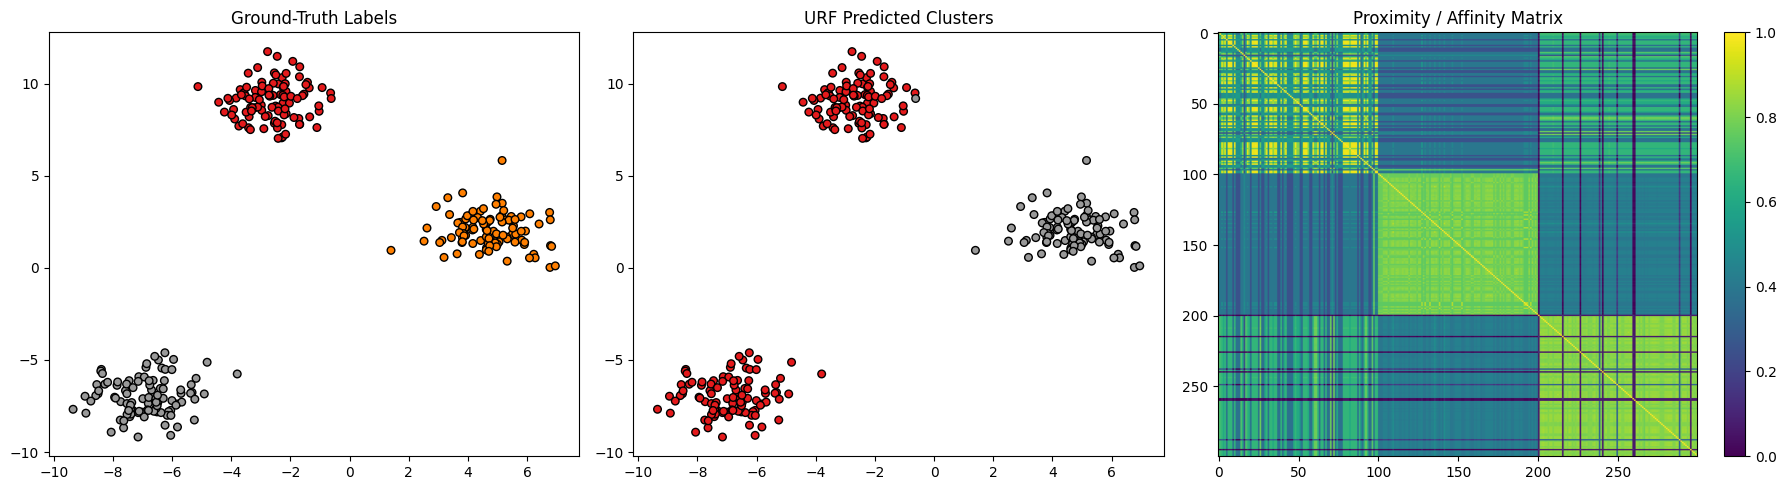

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sktree import UnsupervisedRandomForest
from sklearn.datasets import make_blobs

# Create three well-separated clusters (no labels used for training)
X, y_true = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=42)

# Fit UnsupervisedRandomForest
urf = UnsupervisedRandomForest(
    n_estimators=200,
    random_state=42,
)
urf.fit(X)

# Get the proximity (affinity) matrix
affinity = urf.transform(X)

# Predict cluster labels
y_pred = urf.predict(X)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Ground-truth clusters
axes[0].scatter(X[:, 0], X[:, 1], c=y_true, cmap="Set1", edgecolor="k", s=30)
axes[0].set_title("Ground-Truth Labels")

# 2) URF predicted clusters
axes[1].scatter(X[:, 0], X[:, 1], c=y_pred, cmap="Set1", edgecolor="k", s=30)
axes[1].set_title("URF Predicted Clusters")

# 3) Affinity matrix heatmap (sorted by true label for visual clarity)
order = np.argsort(y_true)
im = axes[2].imshow(affinity[np.ix_(order, order)], cmap="viridis", aspect="auto")
axes[2].set_title("Proximity / Affinity Matrix")
plt.colorbar(im, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.show()